# Basit ve çoklu doğrusal regresyon

**Amaç:** Aynı sayısal hedefi tek değişkenle ve 10 değişkenle tahmin ederek hataları karşılaştırmak.

- Veri: scikit-learn Diabetes; 442 kişi, 10 özellik.
- Hedef: bir yıl sonraki hastalık ilerleme puanı.
- Basit model: yalnız BMI. Çoklu model: 10 özellik.
- Ayrım: 353 eğitim, 89 test (`random_state=42`).

Google Colab veya Jupyter'da hücreleri sırayla çalıştır. CSV veya Python dosyasını ayrıca yüklemek gerekmez; veri scikit-learn içinde hazırdır. Gerekli paketler yoksa ayrı bir hücrede `%pip install numpy pandas matplotlib scikit-learn` çalıştır.

## Projede yolunu bul

[Depo ana sayfası](https://github.com/sanlibrk/Yapay-Sinir-A-lar-A-) · [Adım adım rehber](https://github.com/sanlibrk/Yapay-Sinir-A-lar-A-/blob/main/docs/adim_adim_rehber.md) · [Bilimsel rapor](https://github.com/sanlibrk/Yapay-Sinir-A-lar-A-/blob/main/docs/bilimsel_rapor.md)


## 1. Kütüphaneler
`LinearRegression` katsayıları en küçük kareler yöntemiyle bulur; bu uygulamada epoch ve öğrenme hızı ayarlanmaz.

In [1]:
from pathlib import Path

import matplotlib
matplotlib.use("Agg")  # Grafikler pencere açılmadan dosyaya kaydedilir.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split




## 2. Veri seti
`scaled=False` ham özellikleri alır. Hedef, kan şekeri ölçümü değil hastalık ilerleme puanıdır. Çıktılar notebook çalışma dizinine yazılır.

In [2]:
# 1. Veri seti: 442 kişi, 10 özellik ve tek bir sayısal hedef.
# scaled=False: özelliklerin önceden tüm veriyle ölçeklenmesini önler.
# LinearRegression için bu örnekte standartlaştırma gerekli değildir.
veri = load_diabetes(as_frame=True, scaled=False)
X = veri.data
y = veri.target  # Bir yıl sonraki hastalık ilerleme puanı; kan şekeri değil.

# Notebook/Colab içinde de aynı kod çalışabilir.
cikti = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
cikti.mkdir(parents=True, exist_ok=True)



## 3. Eğitim ve test ayrımı
İki model aynı kişileri eğitimde ve testte kullanır. `sample_id` ve `split` yalnız kayıt içindir; model girdisi değildir.

In [3]:
# 2. Aynı kişileri iki modelde de aynı gruba koyuyoruz.
# sample_id veri satırı kimliğidir; modele girdi olarak verilmez.
egitim_id, test_id = train_test_split(
    np.arange(len(y)), test_size=0.20, random_state=42
)

veri_csv = X.copy()
veri_csv.insert(0, "sample_id", np.arange(len(y)))
veri_csv["disease_progression"] = y
veri_csv["split"] = "train"
veri_csv.loc[test_id, "split"] = "test"
veri_csv.to_csv(cikti / "diabetes_veri_seti.csv", index=False)




## 4. Modelleri eğitme
Basit regresyon: $\hat y=b_0+b_1\,bmi$. Çoklu regresyon: $\hat y=b_0+\sum_{j=1}^{10}b_jx_j$.

Her iki model de **tek bir hedefi** tahmin eder. Katsayılar yalnız eğitim verisiyle öğrenilir.

In [4]:
def hata_olc(y_gercek, y_tahmin):
    """MSE, RMSE, MAE ve R² hesaplar; yüzde doğruluk hesaplamaz."""
    mse = mean_squared_error(y_gercek, y_tahmin)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_gercek, y_tahmin),
        "R2": r2_score(y_gercek, y_tahmin),
    }


# 3. Basit: tek açıklayıcı değişken. Çoklu: 10 açıklayıcı değişken.
# Her iki modelin de çıktı/hedef değişkeni tektir.
ozellikler = {
    "Basit doğrusal regresyon": ["bmi"],
    "Çoklu doğrusal regresyon": list(X.columns),
}
modeller = {}
sonuc_satirlari = []
katsayi_satirlari = []
tahminler = pd.DataFrame({
    "sample_id": test_id,
    "gercek_deger": y.iloc[test_id].to_numpy(),
})

for ad, sutunlar in ozellikler.items():
    X_egitim = X.iloc[egitim_id][sutunlar]
    X_test = X.iloc[test_id][sutunlar]
    y_egitim = y.iloc[egitim_id]

    # fit yalnız eğitim örneklerine bakar. Doğrusal regresyon OLS ile çözülür.
    # Bu kodda öğrenme hızı veya epoch ayarlamıyoruz.
    model = LinearRegression()
    model.fit(X_egitim, y_egitim)
    modeller[ad] = model

    for bolum, girdiler, hedef in [
        ("Eğitim", X_egitim, y_egitim),
        ("Test", X_test, y.iloc[test_id]),
    ]:
        sonuc_satirlari.append({
            "Model": ad,
            "Bolum": bolum,
            "Girdi_sayisi": len(sutunlar),
            "Ornek_sayisi": len(hedef),
            **hata_olc(hedef, model.predict(girdiler)),
        })

    kisa_ad = "basit" if len(sutunlar) == 1 else "coklu"
    tahminler[kisa_ad + "_tahmin"] = model.predict(X_test)
    tahminler[kisa_ad + "_artik"] = (
        tahminler["gercek_deger"] - tahminler[kisa_ad + "_tahmin"]
    )
    katsayi_satirlari.append({"Model": ad, "Terim": "sabit", "Katsayi": model.intercept_})
    for sutun, katsayi in zip(sutunlar, model.coef_):
        katsayi_satirlari.append({"Model": ad, "Terim": sutun, "Katsayi": katsayi})



## 5. Hata ölçümü
MSE, RMSE ve MAE düşük; R² yüksek olduğunda sonuç daha iyidir. R², yüzde doğruluk değildir. Eğitim hatasının yanında, görülmemiş verideki test hatasını değerlendir.

In [5]:
sonuclar = pd.DataFrame(sonuc_satirlari)
sonuclar.to_csv(cikti / "sonuclar.csv", index=False)
tahminler.to_csv(cikti / "test_tahminleri.csv", index=False)
pd.DataFrame(katsayi_satirlari).to_csv(cikti / "katsayilar.csv", index=False)

print(f"Örnek: {len(y)} | Eğitim: {len(egitim_id)} | Test: {len(test_id)}")
print(sonuclar.round(4).to_string(index=False))
basit_model = modeller["Basit doğrusal regresyon"]
print(f"\nBasit model: tahmin = {basit_model.intercept_:.4f} "
      f"+ {basit_model.coef_[0]:.4f} × BMI")
test_sonuclari = sonuclar[sonuclar["Bolum"] == "Test"].reset_index(drop=True)
azalma = 100 * (1 - test_sonuclari.loc[1, "RMSE"] / test_sonuclari.loc[0, "RMSE"])
print(f"Bu test bölünmesinde çoklu modelin RMSE'si %{azalma:.2f} daha düşük.")



Örnek: 442 | Eğitim: 353 | Test: 89
                   Model  Bolum  Girdi_sayisi  Ornek_sayisi       MSE    RMSE     MAE     R2
Basit doğrusal regresyon Eğitim             1           353 3854.1127 62.0815 51.3797 0.3657
Basit doğrusal regresyon   Test             1            89 4061.8259 63.7325 52.2600 0.2334
Çoklu doğrusal regresyon Eğitim            10           353 2868.5497 53.5588 43.4835 0.5279
Çoklu doğrusal regresyon   Test            10            89 2900.1936 53.8534 42.7941 0.4526

Basit model: tahmin = -131.8738 + 10.7628 × BMI
Bu test bölünmesinde çoklu modelin RMSE'si %15.50 daha düşük.


## 6. Grafikler
Kesikli köşegen üzerindeki nokta kusursuz tahmindir. Noktaların doğrudan uzaklığı tahmin hatasını gösterir. Sağ alttaki sütunlarda daha düşük değer daha az hata demektir.


Dosyalar kaydedildi: <notebook çalışma dizini>


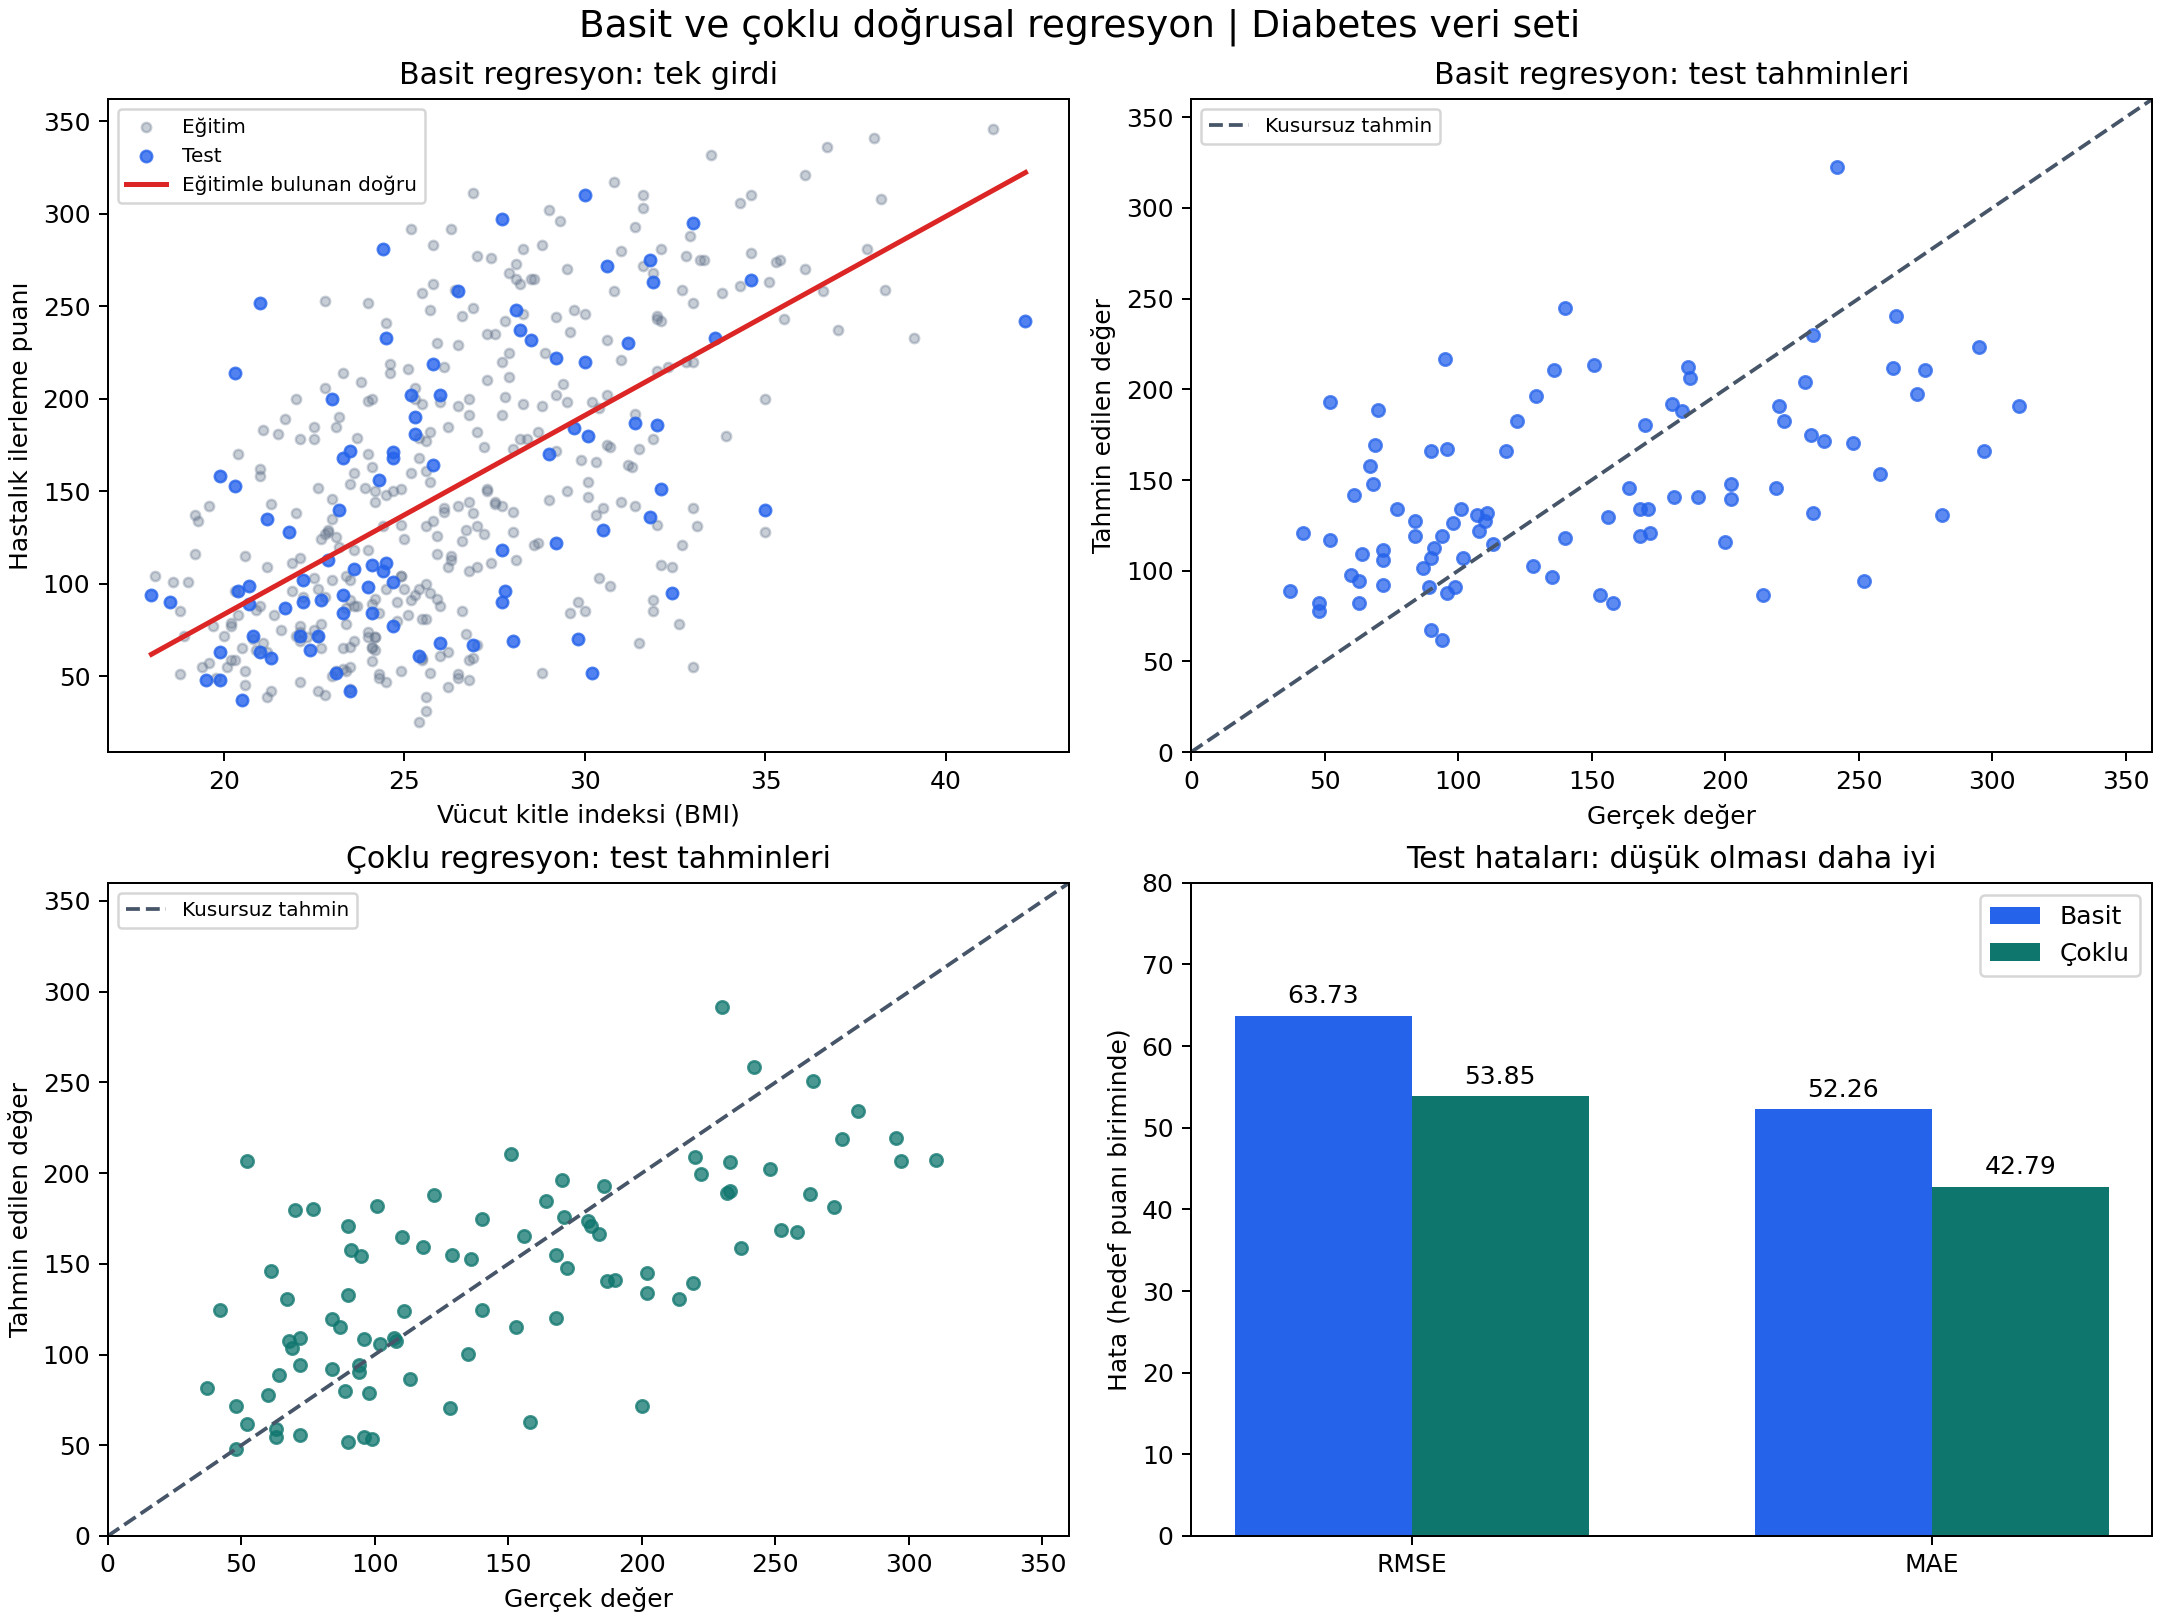

In [6]:
# 4. Grafikler: tek değişkenli doğru, gerçek-tahmin ve hata karşılaştırması.
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, eksenler = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
ax = eksenler[0, 0]
ax.scatter(X.iloc[egitim_id]["bmi"], y.iloc[egitim_id], s=14, alpha=0.35,
           label="Eğitim", color="#64748b")
ax.scatter(X.iloc[test_id]["bmi"], y.iloc[test_id], s=21, alpha=0.8,
           label="Test", color="#2563eb")
bmi_sirasi = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 100)})
ax.plot(bmi_sirasi["bmi"], basit_model.predict(bmi_sirasi),
        color="#dc2626", linewidth=2, label="Eğitimle bulunan doğru")
ax.set(xlabel="Vücut kitle indeksi (BMI)", ylabel="Hastalık ilerleme puanı",
       title="Basit regresyon: tek girdi")
ax.legend(fontsize=8)

for ax, ad, renk in [
    (eksenler[0, 1], "basit", "#2563eb"),
    (eksenler[1, 0], "coklu", "#0f766e"),
]:
    ax.scatter(tahminler["gercek_deger"], tahminler[ad + "_tahmin"],
               s=25, alpha=0.75, color=renk)
    ax.plot([0, 360], [0, 360], "--", color="#475569", label="Kusursuz tahmin")
    ax.set(xlabel="Gerçek değer", ylabel="Tahmin edilen değer",
           title=("Basit" if ad == "basit" else "Çoklu") + " regresyon: test tahminleri",
           xlim=(0, 360), ylim=(0, 360))
    ax.legend(fontsize=8)

ax = eksenler[1, 1]
konum = np.arange(2)
for i, (etiket, renk) in enumerate([("Basit", "#2563eb"), ("Çoklu", "#0f766e")]):
    degerler = test_sonuclari.loc[i, ["RMSE", "MAE"]].astype(float).to_numpy()
    cubuklar = ax.bar(konum + (i - 0.5) * 0.34, degerler, width=0.34,
                      label=etiket, color=renk)
    ax.bar_label(cubuklar, fmt="%.2f", padding=3)
ax.set(xticks=konum, xticklabels=["RMSE", "MAE"], ylabel="Hata (hedef puanı biriminde)",
       title="Test hataları: düşük olması daha iyi", ylim=(0, 80))
ax.legend()
fig.suptitle("Basit ve çoklu doğrusal regresyon | Diabetes veri seti", fontsize=15)
fig.savefig(cikti / "regresyon_grafikleri.png", dpi=180)
plt.close(fig)
print(f"\nDosyalar kaydedildi: {cikti}")

from IPython.display import Image
display(Image(filename=str(cikti / "regresyon_grafikleri.png")))


## Sonuç

Bu test bölünmesinde çoklu regresyonun RMSE değeri **53,85**, basit regresyonunki **63,73** bulundu. RMSE yaklaşık **%15,50** azaldı. Test R² değerleri sırasıyla **0,4526** ve **0,2334** oldu. Çoklu model bu deneyde daha düşük hatayla tahmin yaptı; bu sonuç her veri setinde aynı modelin üstün olacağını göstermez.

RMSE hedefle aynı birimde, MSE ise hedefin karesi birimindedir. Basit/çoklu regresyon ayrımı açıklayıcı değişken sayısıyla ilgilidir; tek/çok katmanlı ağ ayrımı değildir.

Kaynaklar: [scikit-learn Diabetes](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset), [özgün veri sayfası](https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html).
